# Part II — PyTorch CNN: formal CIFAR10 experiments

This is the full-data results notebook for the lecture-specified CNN. The earlier tiny-data engineering check is preserved separately in `cnn_smoke_checks.ipynb`. The shared MLP/CNN comparison and high-confidence error images are in the root `cifar_experiments.ipynb`.

**Task 1:** eight Conv2d → BatchNorm2d → ReLU blocks, five max pools, flatten and Linear(512,10). Convolutions use kernel 3, stride 1, padding 1; max pools use kernel 3, stride 2, padding 1. Unspecified settings and initialization remain PyTorch defaults.

**Task 2:** Adam with its default learning rate 0.001 and default remaining settings, minibatches of 32, stratified 45,000/5,000 train/validation split and separate 10,000-example test set. Both 5,000- and 20,000-update runs use seed 42. The best checkpoint maximizes validation accuracy, breaking ties with lower validation loss; test results never select a checkpoint.

In [1]:
from pathlib import Path
import json,sys
import torch
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display,Markdown
PART=Path.cwd() if (Path.cwd()/'cnn_model.py').exists() else Path.cwd()/'Part 2'
ROOT=PART.parent
sys.path[:0]=[str(ROOT.resolve()),str(PART.resolve())]
from cnn_model import CNN
from cifar_experiments import train
torch.set_num_threads(1)
RUN_TRAINING=False  # Explicit opt-in; default analysis does not retrain.
if RUN_TRAINING:
    train(architecture='cnn',steps=5000,eval_freq=500,device='cpu')
model=CNN().eval()
rows=['| Layer | Input → output | Parameter shapes | Count |','|---|---|---|---:|']
handles=[]
def capture(name):
    def hook(module,args,out):
        params=list(module.named_parameters(recurse=False))
        rows.append(f'| {name}: {type(module).__name__} | {tuple(args[0].shape)} → {tuple(out.shape)} | '+', '.join(f'{n}: {tuple(p.shape)}' for n,p in params)+f' | {sum(p.numel() for _,p in params)} |')
    return hook
for name,module in model.named_modules():
    if not list(module.children()): handles.append(module.register_forward_hook(capture(name)))
with torch.no_grad(): assert model(torch.zeros(2,3,32,32)).shape==(2,10)
for handle in handles: handle.remove()
display(Markdown('\n'.join(rows)))
print('Trainable parameters:',sum(p.numel() for p in model.parameters()))
assert sum(p.numel() for p in model.parameters())==9231114

/opt/homebrew/Caskroom/miniconda/base/envs/mldl/lib/python3.11/site-packages/torchvision/io/image.py:14: UserWarning: Failed to load image Python extension: 'dlopen(/opt/homebrew/Caskroom/miniconda/base/envs/mldl/lib/python3.11/site-packages/torchvision/image.so, 0x0006): Library not loaded: @rpath/libjpeg.9.dylib
  Referenced from: <EB3FF92A-5EB1-3EE8-AF8B-5923C1265422> /opt/homebrew/Caskroom/miniconda/base/envs/mldl/lib/python3.11/site-packages/torchvision/image.so
  Reason: tried: '/opt/homebrew/Caskroom/miniconda/base/envs/mldl/lib/python3.11/site-packages/torchvision/../../../libjpeg.9.dylib' (no such file), '/opt/homebrew/Caskroom/miniconda/base/envs/mldl/lib/python3.11/site-packages/torchvision/../../../libjpeg.9.dylib' (no such file), '/opt/homebrew/Caskroom/miniconda/base/envs/mldl/lib/python3.11/lib-dynload/../../libjpeg.9.dylib' (no such file), '/opt/homebrew/Caskroom/miniconda/base/envs/mldl/bin/../lib/libjpeg.9.dylib' (no such file)'If you don't plan on using image functio

| Layer | Input → output | Parameter shapes | Count |
|---|---|---|---:|
| features.0: Conv2d | (2, 3, 32, 32) → (2, 64, 32, 32) | weight: (64, 3, 3, 3), bias: (64,) | 1792 |
| features.1: BatchNorm2d | (2, 64, 32, 32) → (2, 64, 32, 32) | weight: (64,), bias: (64,) | 128 |
| features.2: ReLU | (2, 64, 32, 32) → (2, 64, 32, 32) |  | 0 |
| features.3: MaxPool2d | (2, 64, 32, 32) → (2, 64, 16, 16) |  | 0 |
| features.4: Conv2d | (2, 64, 16, 16) → (2, 128, 16, 16) | weight: (128, 64, 3, 3), bias: (128,) | 73856 |
| features.5: BatchNorm2d | (2, 128, 16, 16) → (2, 128, 16, 16) | weight: (128,), bias: (128,) | 256 |
| features.6: ReLU | (2, 128, 16, 16) → (2, 128, 16, 16) |  | 0 |
| features.7: MaxPool2d | (2, 128, 16, 16) → (2, 128, 8, 8) |  | 0 |
| features.8: Conv2d | (2, 128, 8, 8) → (2, 256, 8, 8) | weight: (256, 128, 3, 3), bias: (256,) | 295168 |
| features.9: BatchNorm2d | (2, 256, 8, 8) → (2, 256, 8, 8) | weight: (256,), bias: (256,) | 512 |
| features.10: ReLU | (2, 256, 8, 8) → (2, 256, 8, 8) |  | 0 |
| features.11: Conv2d | (2, 256, 8, 8) → (2, 256, 8, 8) | weight: (256, 256, 3, 3), bias: (256,) | 590080 |
| features.12: BatchNorm2d | (2, 256, 8, 8) → (2, 256, 8, 8) | weight: (256,), bias: (256,) | 512 |
| features.13: ReLU | (2, 256, 8, 8) → (2, 256, 8, 8) |  | 0 |
| features.14: MaxPool2d | (2, 256, 8, 8) → (2, 256, 4, 4) |  | 0 |
| features.15: Conv2d | (2, 256, 4, 4) → (2, 512, 4, 4) | weight: (512, 256, 3, 3), bias: (512,) | 1180160 |
| features.16: BatchNorm2d | (2, 512, 4, 4) → (2, 512, 4, 4) | weight: (512,), bias: (512,) | 1024 |
| features.17: ReLU | (2, 512, 4, 4) → (2, 512, 4, 4) |  | 0 |
| features.18: Conv2d | (2, 512, 4, 4) → (2, 512, 4, 4) | weight: (512, 512, 3, 3), bias: (512,) | 2359808 |
| features.19: BatchNorm2d | (2, 512, 4, 4) → (2, 512, 4, 4) | weight: (512,), bias: (512,) | 1024 |
| features.20: ReLU | (2, 512, 4, 4) → (2, 512, 4, 4) |  | 0 |
| features.21: MaxPool2d | (2, 512, 4, 4) → (2, 512, 2, 2) |  | 0 |
| features.22: Conv2d | (2, 512, 2, 2) → (2, 512, 2, 2) | weight: (512, 512, 3, 3), bias: (512,) | 2359808 |
| features.23: BatchNorm2d | (2, 512, 2, 2) → (2, 512, 2, 2) | weight: (512,), bias: (512,) | 1024 |
| features.24: ReLU | (2, 512, 2, 2) → (2, 512, 2, 2) |  | 0 |
| features.25: Conv2d | (2, 512, 2, 2) → (2, 512, 2, 2) | weight: (512, 512, 3, 3), bias: (512,) | 2359808 |
| features.26: BatchNorm2d | (2, 512, 2, 2) → (2, 512, 2, 2) | weight: (512,), bias: (512,) | 1024 |
| features.27: ReLU | (2, 512, 2, 2) → (2, 512, 2, 2) |  | 0 |
| features.28: MaxPool2d | (2, 512, 2, 2) → (2, 512, 1, 1) |  | 0 |
| classifier: Linear | (2, 512) → (2, 10) | weight: (10, 512), bias: (10,) | 5130 |

Trainable parameters: 9231114


The five pooling outputs have shapes `(B,64,16,16)`, `(B,128,8,8)`, `(B,256,4,4)`, `(B,512,2,2)` and `(B,512,1,1)`. The explicit flatten operation between the final pool and classifier maps to `(B,512)`; it is a tensor operation and is not shown as a separate module hook above.

A convolution can be viewed as multiplying unfolded patches `(B*H*W, 9*C_in)` by transposed weights `(9*C_in, C_out)`, then reshaping. Each weight gradient has the original parameter shape. BatchNorm has trainable scale/offset vectors but nontrainable running-statistic buffers. Evaluation uses `eval()` and restores the previous mode, so validation images do not update these buffers. Cross-entropy consumes `(B,10)` logits and integer targets `(B,)`, producing a scalar loss. Adam's moment tensors match each parameter's shape.

In [2]:
extended=json.loads((ROOT/'results/cifar_extended_study.json').read_text())
assert extended['status']=='complete'
folders=[ROOT/'Part 2/results/cifar_validation/baseline-seed42-5w7dbk9j',ROOT/next(r['run'] for r in extended['records'] if r['architecture']=='cnn')]
runs=[(folder,json.loads((folder/'history.json').read_text()),json.loads((folder/'test_metrics.json').read_text())) for folder in folders]
rows=['| Budget | Selected update | Train | Validation | Test | Test CE | PyTorch |','|---:|---:|---:|---:|---:|---:|---|']
for folder,run,metric in runs:
    assert run['status']=='complete'
    best=next(r for r in run['history'] if r['step']==run['best_step'])
    rows.append(f"| {run['config']['steps']} | {run['best_step']} | {best['train_accuracy']:.2%} | {best['val_accuracy']:.2%} | {metric['test_accuracy']:.2%} | {metric['test_loss']:.4f} | {run['config']['torch_version']} |")
display(Markdown('\n'.join(rows)))

| Budget | Selected update | Train | Validation | Test | Test CE | PyTorch |
|---:|---:|---:|---:|---:|---:|---|
| 5000 | 5000 | 83.92% | 79.64% | 79.24% | 0.6289 | 2.10.0+cu128 |
| 20000 | 16000 | 97.22% | 83.68% | 82.83% | 0.6970 | 2.8.0+cu128 |

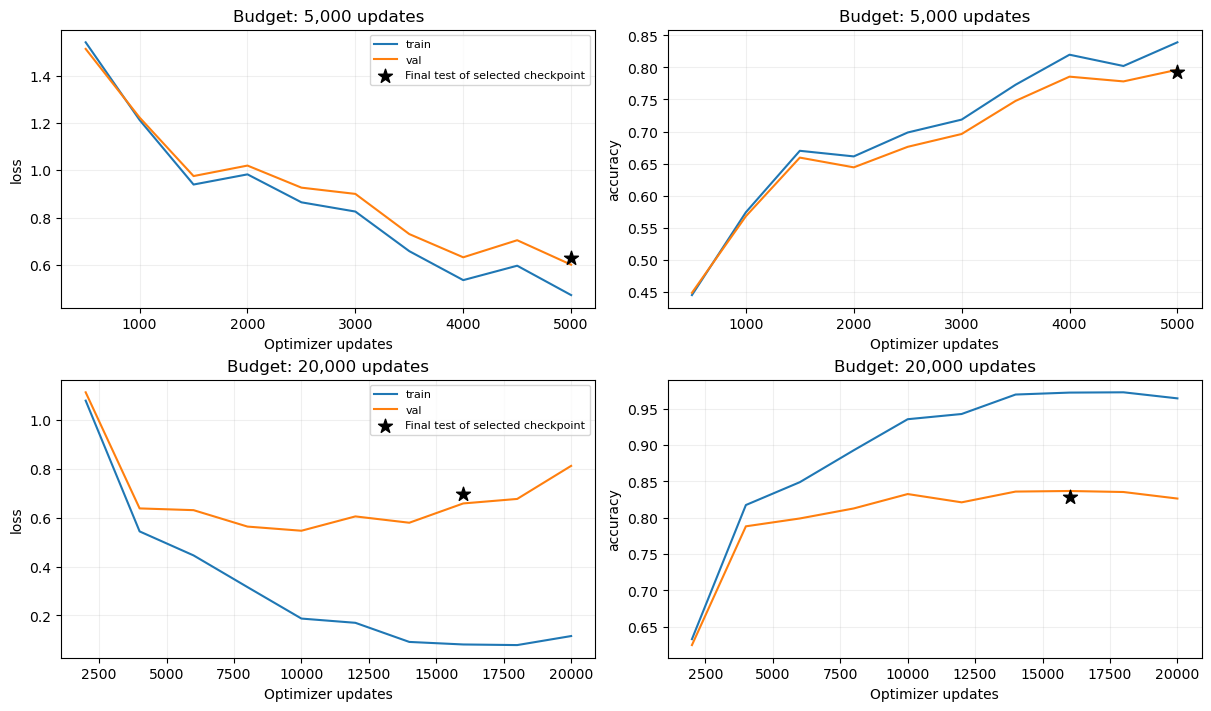

In [3]:
fig,axes=plt.subplots(2,2,figsize=(12,7),constrained_layout=True)
for row,(folder,run,metric) in enumerate(runs):
    history=run['history']
    for ax,quantity in zip(axes[row],['loss','accuracy']):
        for split in ['train','val']:
            ax.plot([r['step'] for r in history],[r[split+'_'+quantity] for r in history],label=split)
        ax.scatter([metric['checkpoint_step']],[metric['test_'+quantity]],marker='*',s=110,label='Final test of selected checkpoint',color='black',zorder=5)
        ax.set(xlabel='Optimizer updates',ylabel=quantity,title=f"Budget: {run['config']['steps']:,} updates")
        ax.grid(alpha=0.2)
    axes[row,0].legend(fontsize=8)
fig.savefig(PART/'results/cnn_formal_curves.png',dpi=160)
plt.show()

5000 updates: per-class recall {'airplane': 0.811, 'automobile': 0.837, 'bird': 0.659, 'cat': 0.643, 'deer': 0.761, 'dog': 0.683, 'frog': 0.843, 'horse': 0.9, 'ship': 0.901, 'truck': 0.886}
20000 updates: per-class recall {'airplane': 0.83, 'automobile': 0.921, 'bird': 0.743, 'cat': 0.561, 'deer': 0.82, 'dog': 0.831, 'frog': 0.847, 'horse': 0.896, 'ship': 0.915, 'truck': 0.919}


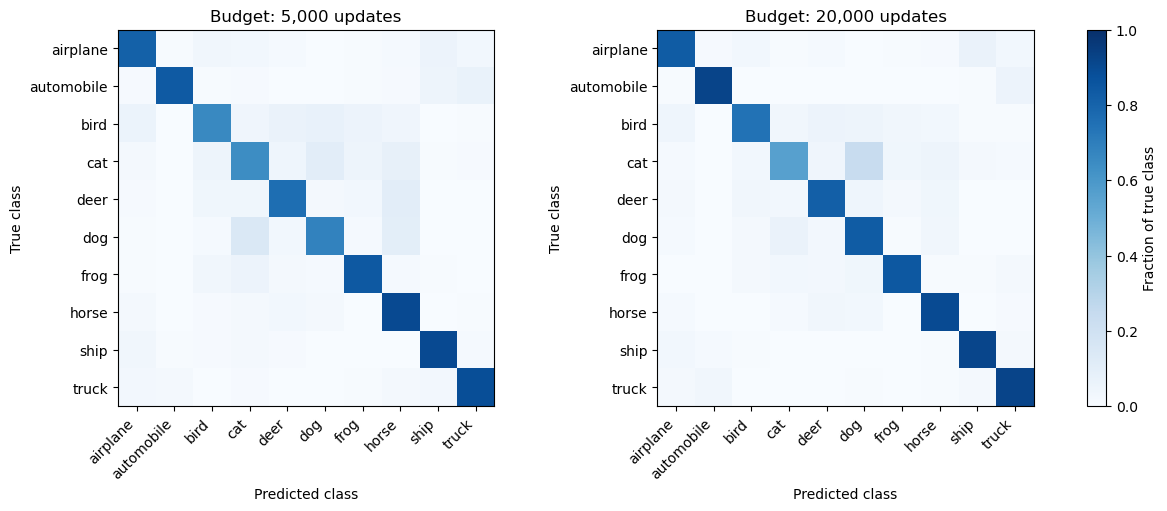

In [4]:
fig,axes=plt.subplots(1,2,figsize=(12,5),constrained_layout=True)
for ax,(folder,run,metric) in zip(axes,runs):
    cm=np.array(metric['confusion_matrix'])
    im=ax.imshow(cm/cm.sum(1,keepdims=True),vmin=0,vmax=1,cmap='Blues')
    ax.set(xticks=range(10),yticks=range(10),xticklabels=metric['classes'],yticklabels=metric['classes'],xlabel='Predicted class',ylabel='True class',title=f"Budget: {run['config']['steps']:,} updates")
    plt.setp(ax.get_xticklabels(),rotation=45,ha='right')
    print(run['config']['steps'],'updates: per-class recall',dict(zip(metric['classes'],(cm.diagonal()/cm.sum(1)).round(4))))
fig.colorbar(im,ax=axes,label='Fraction of true class')
fig.savefig(PART/'results/cnn_confusion_comparison.png',dpi=160)
plt.show()

## Interpretation

The initial run achieves 79.24% test accuracy. The 20,000-update run selects update 16,000 using validation accuracy and achieves 82.83% test accuracy. Its selected training accuracy is 97.22%, compared with 83.68% validation accuracy, showing a substantial generalization gap.

Test cross-entropy increases from about 0.6289 to 0.6970 despite higher accuracy. Cross-entropy penalizes confidently assigning low probability to the true class; improved accuracy does not guarantee improved confidence quality. A separate calibration analysis would be needed to quantify calibration.

These stages use different PyTorch versions, so they are not a strictly isolated causal test of training duration. The matched 20,000-update MLP/CNN pair does share a hardware/software environment, data split and update budget: its MLP test accuracy is 52.30%. The CNN differs in parameter count, depth, locality, weight sharing and normalization, so the comparison does not isolate convolution alone. Both image-model studies use one seed; robustness across seeds remains unmeasured.